# Impacto del uso de redes sociales

El presente trabajo busca analizar el impacto de la exposición a plataformas de "Social Media" en la vida de jovenes estudiantes.

Se miden principalmente la interacción de las horas de uso de redes sociales y factores considerados clave para analizar la calidad de vida de un estudiante:
- Horas de duración y calidad autopercibida del sueño
- Frecuencia de comparación social
- Nivel de estrés percibido
- Índice de salud mental
- Performance académica: promedio de calificaciones
- Impacto general

Los datos fueron extraídos de Kaggle.com
Las herramientas a utilizar son Python, Pandas, Matplotlib, Seaborn, Power Bi

In [17]:
# Cargar csv, traducir columnas y valores categóricos al castellano desde el inicio
import pandas as pd

df = pd.read_csv("/content/Social_media_impact_on_life.csv")

# 1. Diccionario de traducción de columnas
traduccion_columnas = {
    'Student_ID': 'ID_Estudiante',
    'Age': 'Edad',
    'Gender': 'Genero',
    'Academic_Level': 'Nivel_Academico',
    'Primary_Platform': 'Plataforma_Principal',
    'Daily_Usage_Hours': 'Horas_Uso_Diario',
    'Weekend_Extra_Hours': 'Horas_Extra_Fin_De_Semana',
    'Device_Type': 'Tipo_Dispositivo',
    'Sleep_Duration_Hours': 'Horas_Duracion_Sueno',
    'Sleep_Quality_Score': 'Puntaje_Calidad_Sueno',
    'Late_Night_Usage': 'Uso_Nocturno',
    'Social_Comparison_Frequency': 'Frecuencia_Comparacion_Social',
    'Perceived_Stress_Score': 'Puntaje_Estres_Percibido',
    'Mental_Health_Index': 'Indice_Salud_Mental',
    'Academic_Performance_GPA': 'Rendimiento_Academico_GPA',
    'Overall_Impact': 'Impacto_General'
}

df.rename(columns=traduccion_columnas, inplace=True)

# 2. Diccionarios de traducción para los datos internos
traduccion_genero = {
    'Female': 'Femenino',
    'Male': 'Masculino',
    'Non-Binary': 'No Binario',
    'Prefer not to say': 'Prefiero no decirlo'
}

traduccion_nivel = {
    'High School': 'Secundaria',
    'Undergraduate': 'Pregrado',
    'Postgraduate': 'Posgrado'
}

traduccion_uso_nocturno = {
    True: 'Sí',
    False: 'No'
}

traduccion_comparacion = {
    'Always': 'Siempre',
    'Frequently': 'Frecuentemente',
    'Sometimes': 'A veces',
    'Rarely': 'Raras veces',
    'Never': 'Nunca'
}

traduccion_impacto = {
    'Beneficial': 'Beneficioso',
    'Neutral': 'Neutral',
    'Negative': 'Negativo'
}

# Aplicar las traducciones a los valores de las columnas
df['Genero'] = df['Genero'].map(traduccion_genero).fillna(df['Genero'])
df['Nivel_Academico'] = df['Nivel_Academico'].map(traduccion_nivel).fillna(df['Nivel_Academico'])
df['Uso_Nocturno'] = df['Uso_Nocturno'].map(traduccion_uso_nocturno).fillna(df['Uso_Nocturno'])
df['Frecuencia_Comparacion_Social'] = df['Frecuencia_Comparacion_Social'].map(traduccion_comparacion).fillna(df['Frecuencia_Comparacion_Social'])
df['Impacto_General'] = df['Impacto_General'].map(traduccion_impacto).fillna(df['Impacto_General'])

print("Columnas y valores traducidos correctamente al castellano.")

Columnas y valores traducidos correctamente al castellano.


In [18]:
# Inspección básica del dataset:
print("Filas y columnas:",df.shape)     #filas,columnas
print("Nombres de columnas:", df.columns)   #nombres de columnas
df.head(5)

Filas y columnas: (4500, 16)
Nombres de columnas: Index(['ID_Estudiante', 'Edad', 'Genero', 'Nivel_Academico',
       'Plataforma_Principal', 'Horas_Uso_Diario', 'Horas_Extra_Fin_De_Semana',
       'Tipo_Dispositivo', 'Horas_Duracion_Sueno', 'Puntaje_Calidad_Sueno',
       'Uso_Nocturno', 'Frecuencia_Comparacion_Social',
       'Puntaje_Estres_Percibido', 'Indice_Salud_Mental',
       'Rendimiento_Academico_GPA', 'Impacto_General'],
      dtype='object')


,ID_Estudiante,Edad,Genero,Nivel_Academico,Plataforma_Principal,Horas_Uso_Diario,Horas_Extra_Fin_De_Semana,Tipo_Dispositivo,Horas_Duracion_Sueno,Puntaje_Calidad_Sueno,Uso_Nocturno,Frecuencia_Comparacion_Social,Puntaje_Estres_Percibido,Indice_Salud_Mental,Rendimiento_Academico_GPA,Impacto_General
0,STU_2024000,19,Femenino,Pregrado,Snapchat,7.5,1.5,Smartphone,5.9,2,Sí,Siempre,20.0,73,2.73,Neutral
1,STU_2024001,19,Femenino,Pregrado,Instagram,4.6,1.3,Smartphone,7.9,3,Sí,A veces,17.0,90,3.21,Beneficioso
2,STU_2024002,17,Femenino,Secundaria,TikTok,10.9,1.7,Smartphone,5.2,1,Sí,Frecuentemente,18.0,70,3.00,Neutral
3,STU_2024003,16,Femenino,Secundaria,YouTube,6.0,2.3,Tablet,7.6,4,Sí,A veces,15.0,82,3.42,Beneficioso
4,STU_2024004,17,Masculino,Secundaria,LinkedIn,3.3,2.6,Smartphone,7.6,4,Sí,Nunca,16.0,84,3.41,Beneficioso


In [19]:
df.tail(5)

,ID_Estudiante,Edad,Genero,Nivel_Academico,Plataforma_Principal,Horas_Uso_Diario,Horas_Extra_Fin_De_Semana,Tipo_Dispositivo,Horas_Duracion_Sueno,Puntaje_Calidad_Sueno,Uso_Nocturno,Frecuencia_Comparacion_Social,Puntaje_Estres_Percibido,Indice_Salud_Mental,Rendimiento_Academico_GPA,Impacto_General
4495,STU_2028495,16,Masculino,Secundaria,YouTube,5.8,1.2,Smartphone,7.8,3,Sí,A veces,11.0,79,2.85,Beneficioso
4496,STU_2028496,19,Femenino,Pregrado,LinkedIn,3.8,3.0,Smartphone,6.6,3,No,Frecuentemente,9.0,83,3.37,Beneficioso
4497,STU_2028497,19,Masculino,Pregrado,Instagram,7.7,1.1,Smartphone,6.0,2,Sí,Frecuentemente,13.0,73,3.16,Beneficioso
4498,STU_2028498,16,Masculino,Secundaria,LinkedIn,4.6,3.3,Laptop/PC,7.1,3,No,A veces,22.0,87,3.50,Beneficioso
4499,STU_2028499,24,Masculino,Pregrado,Instagram,1.8,2.1,Smartphone,6.8,3,Sí,Frecuentemente,10.0,98,3.73,Beneficioso


In [20]:
df.sample(5, random_state=8039)


,ID_Estudiante,Edad,Genero,Nivel_Academico,Plataforma_Principal,Horas_Uso_Diario,Horas_Extra_Fin_De_Semana,Tipo_Dispositivo,Horas_Duracion_Sueno,Puntaje_Calidad_Sueno,Uso_Nocturno,Frecuencia_Comparacion_Social,Puntaje_Estres_Percibido,Indice_Salud_Mental,Rendimiento_Academico_GPA,Impacto_General
4205,STU_2028205,18,Masculino,Secundaria,TikTok,4.6,1.6,Smartphone,7.8,3,No,A veces,16.0,85,4.00,Beneficioso
838,STU_2024838,17,Femenino,Secundaria,Instagram,5.1,1.2,Smartphone,7.2,4,Sí,Nunca,14.0,71,3.07,Beneficioso
2704,STU_2026704,17,Masculino,Secundaria,TikTok,9.6,0.5,Smartphone,5.1,1,Sí,A veces,25.0,54,2.98,Neutral
253,STU_2024253,18,Femenino,Pregrado,YouTube,13.4,2.0,Smartphone,4.0,1,No,Raras veces,25.0,48,2.50,Negativo
3894,STU_2027894,15,Femenino,Secundaria,Instagram,5.1,1.9,Smartphone,6.3,2,Sí,A veces,10.0,81,3.07,Beneficioso


In [21]:
#Chequear metadatos
df.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ID_Estudiante                  4500 non-null   object 
 1   Edad                           4500 non-null   int64  
 2   Genero                         4500 non-null   object 
 3   Nivel_Academico                4500 non-null   object 
 4   Plataforma_Principal           4500 non-null   object 
 5   Horas_Uso_Diario               4500 non-null   float64
 6   Horas_Extra_Fin_De_Semana      4500 non-null   float64
 7   Tipo_Dispositivo               4500 non-null   object 
 8   Horas_Duracion_Sueno           4500 non-null   float64
 9   Puntaje_Calidad_Sueno          4500 non-null   int64  
 10  Uso_Nocturno                   4500 non-null   object 
 11  Frecuencia_Comparacion_Social  4500 non-null   object 
 12  Puntaje_Estres_Percibido       4454 non-null   f

In [22]:
df.describe()

,Edad,Horas_Uso_Diario,Horas_Extra_Fin_De_Semana,Horas_Duracion_Sueno,Puntaje_Calidad_Sueno,Puntaje_Estres_Percibido,Indice_Salud_Mental,Rendimiento_Academico_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


3.1. Identificación y tratamiento de valores faltantes, duplicados y outliers

In [23]:
df.isna().sum().sort_values(ascending=False)

,0
Rendimiento_Academico_GPA,85
Puntaje_Estres_Percibido,46
ID_Estudiante,0
Edad,0
Plataforma_Principal,0
Horas_Uso_Diario,0
Genero,0
Nivel_Academico,0
Tipo_Dispositivo,0
Horas_Extra_Fin_De_Semana,0


In [24]:
#Visualizar nulos en columna Rendimiento Académico:
df[df["Rendimiento_Academico_GPA"].isna()]

,ID_Estudiante,Edad,Genero,Nivel_Academico,Plataforma_Principal,Horas_Uso_Diario,Horas_Extra_Fin_De_Semana,Tipo_Dispositivo,Horas_Duracion_Sueno,Puntaje_Calidad_Sueno,Uso_Nocturno,Frecuencia_Comparacion_Social,Puntaje_Estres_Percibido,Indice_Salud_Mental,Rendimiento_Academico_GPA,Impacto_General
39,STU_2024039,17,Masculino,Secundaria,TikTok,3.3,1.7,Laptop/PC,6.0,1,No,Frecuentemente,15.0,87,NaN,Beneficioso
44,STU_2024044,21,Femenino,Pregrado,Instagram,7.6,1.6,Smartphone,5.9,1,Sí,Raras veces,25.0,70,NaN,Neutral
100,STU_2024100,19,Masculino,Pregrado,Snapchat,6.4,2.7,Laptop/PC,5.4,1,Sí,A veces,16.0,67,NaN,Beneficioso
104,STU_2024104,20,Masculino,Pregrado,YouTube,3.2,3.0,Smartphone,6.4,2,No,Raras veces,11.0,74,NaN,Beneficioso
150,STU_2024150,17,Masculino,Secundaria,Instagram,6.2,2.7,Smartphone,6.3,2,Sí,Siempre,17.0,70,NaN,Beneficioso
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4352,STU_2028352,23,Prefiero no decirlo,Pregrado,Instagram,2.6,1.7,Smartphone,9.1,3,Sí,Raras veces,1.0,98,NaN,Beneficioso
4380,STU_2028380,18,Femenino,Secundaria,TikTok,4.7,2.2,Smartphone,6.7,3,No,Frecuentemente,14.0,70,NaN,Beneficioso
4412,STU_2028412,19,Masculino,Pregrado,TikTok,4.0,2.8,Smartphone,7.6,3,Sí,Raras veces,12.0,89,NaN,Beneficioso
4452,STU_2028452,24,Femenino,Pregrado,YouTube,3.6,1.4,Laptop/PC,7.7,3,Sí,Frecuentemente,11.0,92,NaN,Beneficioso


El database presenta dos columnas con datos faltantes: promedio académico y nivel de stress percibido, como son cantidades mínimas sobre el total de datos (85 y 46 sobre 4500), van a ser reemplazadas por el promedio de cada variable en ambos casos:

In [25]:
#Reemplazo de valores nulos por el promedio en cada caso:
df["Rendimiento_Academico_GPA"] = df["Rendimiento_Academico_GPA"].fillna(df["Rendimiento_Academico_GPA"].mean())
df["Puntaje_Estres_Percibido"] = df["Puntaje_Estres_Percibido"].fillna(df["Puntaje_Estres_Percibido"].mean())

In [26]:
#Confirmación de que ya no existen valores nulos:
df.isna().sum().sort_values(ascending=False)

,0
ID_Estudiante,0
Edad,0
Genero,0
Nivel_Academico,0
Plataforma_Principal,0
Horas_Uso_Diario,0
Horas_Extra_Fin_De_Semana,0
Tipo_Dispositivo,0
Horas_Duracion_Sueno,0
Puntaje_Calidad_Sueno,0


In [27]:
# Identificar como están compuestas las columnas de datos categóricos:
columnas_categoricas = df.select_dtypes(include=['object', 'bool']).columns.tolist()
if 'ID_Estudiante' in columnas_categoricas:
    columnas_categoricas.remove('ID_Estudiante')

# Mostrar valores únicos y distribución para cada una
for col in columnas_categoricas:
    print(f"=== Variable: {col} ===")
    print("Valores únicos:", df[col].unique())
    print("\nDistribución:")
    display(df[col].value_counts())
    print("\n" + "="*40 + "\n")

=== Variable: Genero ===
Valores únicos: ['Femenino' 'Masculino' 'No Binario' 'Prefiero no decirlo']

Distribución:


,count
Genero,
Femenino,2234
Masculino,2051
No Binario,122
Prefiero no decirlo,93




=== Variable: Nivel_Academico ===
Valores únicos: ['Pregrado' 'Secundaria' 'Posgrado']

Distribución:


,count
Nivel_Academico,
Pregrado,2777
Secundaria,1477
Posgrado,246




=== Variable: Plataforma_Principal ===
Valores únicos: ['Snapchat' 'Instagram' 'TikTok' 'YouTube' 'LinkedIn' 'Reddit'
 'X (Twitter)']

Distribución:


,count
Plataforma_Principal,
Instagram,1453
TikTok,1226
YouTube,818
Snapchat,472
Reddit,229
X (Twitter),206
LinkedIn,96


... (4 outputs left out)



=== Variable: Frecuencia_Comparacion_Social ===
Valores únicos: ['Siempre' 'A veces' 'Frecuentemente' 'Nunca' 'Raras veces']

Distribución:


,count
Frecuencia_Comparacion_Social,
A veces,1594
Frecuentemente,1248
Raras veces,766
Siempre,632
Nunca,260




=== Variable: Impacto_General ===
Valores únicos: ['Neutral' 'Beneficioso' 'Negativo']

Distribución:


,count
Impacto_General,
Beneficioso,3681
Neutral,654
Negativo,165


In [28]:
#Correlación entre horas de uso diario, indice de salud mental y rendimiento académico:
df[["Horas_Uso_Diario", "Indice_Salud_Mental", "Rendimiento_Academico_GPA"]].corr().round(2)

,Horas_Uso_Diario,Indice_Salud_Mental,Rendimiento_Academico_GPA
Horas_Uso_Diario,1.00,-0.85,-0.70
Indice_Salud_Mental,-0.85,1.00,0.65
Rendimiento_Academico_GPA,-0.70,0.65,1.00


In [29]:
# Se cruzan las variables de Género y Plataforma Primaria para evaluar posibles diferencias
pd.crosstab(df['Genero'], df['Plataforma_Principal'])

Plataforma_Principal,Instagram,LinkedIn,Reddit,Snapchat,TikTok,X (Twitter),YouTube
Genero,,,,,,,
Femenino,730,54,108,228,607,106,401
Masculino,642,40,107,216,570,91,385
No Binario,45,0,8,20,29,3,17
Prefiero no decirlo,36,2,6,8,20,6,15


In [30]:
# Se cruzan las variables de Frecuencia de comparación social y Nivel académico
pd.crosstab(df['Frecuencia_Comparacion_Social'], df['Nivel_Academico'])

Nivel_Academico,Posgrado,Pregrado,Secundaria
Frecuencia_Comparacion_Social,,,
A veces,86,998,510
Frecuentemente,72,761,415
Nunca,20,167,73
Raras veces,38,468,260
Siempre,30,383,219


In [31]:
# Se cruzan las variables "Frecuencia de comparación social" y "Edad"
pd.crosstab(df['Frecuencia_Comparacion_Social'], df['Edad'])

Edad,15,16,17,18,19,20,21,22,23,24,25,26
Frecuencia_Comparacion_Social,,,,,,,,,,,,
A veces,52,133,230,372,324,225,134,57,30,17,7,13
Frecuentemente,54,87,208,292,250,166,85,55,24,15,5,7
Nunca,7,15,41,65,42,37,28,14,4,2,3,2
Raras veces,31,58,120,178,147,108,63,33,13,10,3,2
Siempre,20,47,117,121,139,94,46,19,14,6,4,5


4.1. Creación de gráficos básicos

In [32]:
import pandas as pd                 # tablas de datos
import matplotlib.pyplot as plt     # gráficos: la base
import seaborn as sns               # gráficos estadísticos, menos código
import plotly.express as px         # gráficos interactivos

# Estilo prolijo para todos los gráficos de Matplotlib y Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)   # tamaño por defecto (ancho, alto)

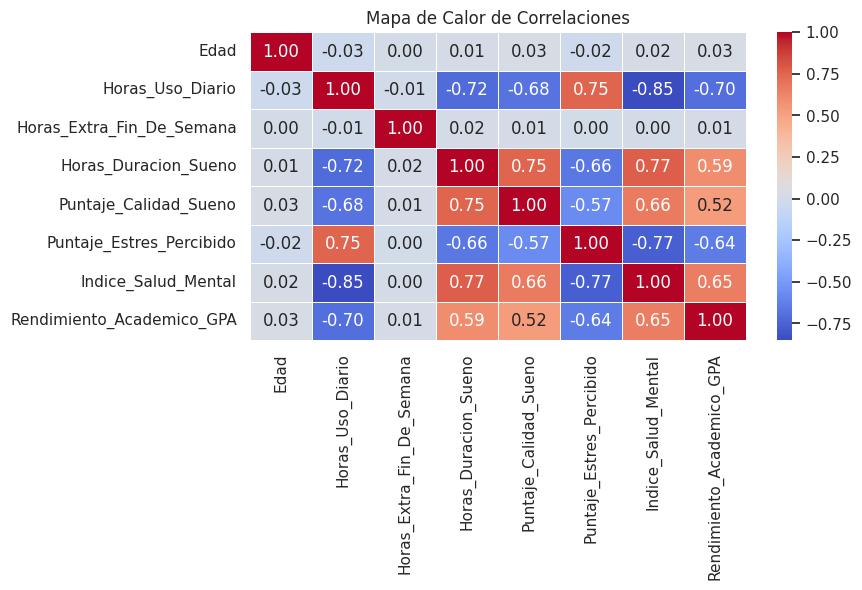

In [33]:
# Seleccionar solo las columnas numéricas para calcular la correlación
columnas_numericas = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = columnas_numericas.corr()

# Mapa de calor de correlaciones entre todas las variables numéricas
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Mapa de Calor de Correlaciones")
plt.show()

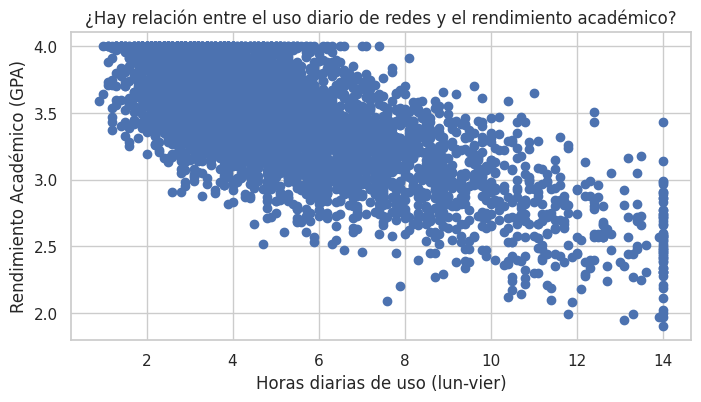

El gráfico de dispersión expone con claridad lo que vimos con los índices de correlación:
una relación inversa entre cantidad de horas de uso de redes sociales y rendimiento académico


In [34]:
# Comparación entre horas de uso diario de redes y el rendimiento académico
plt.scatter(df["Horas_Uso_Diario"], df["Rendimiento_Academico_GPA"])
plt.title("¿Hay relación entre el uso diario de redes y el rendimiento académico?")
plt.xlabel("Horas diarias de uso (lun-vier)")
plt.ylabel("Rendimiento Académico (GPA)")
plt.show()

print("El gráfico de dispersión expone con claridad lo que vimos con los índices de correlación:")
print("una relación inversa entre cantidad de horas de uso de redes sociales y rendimiento académico")

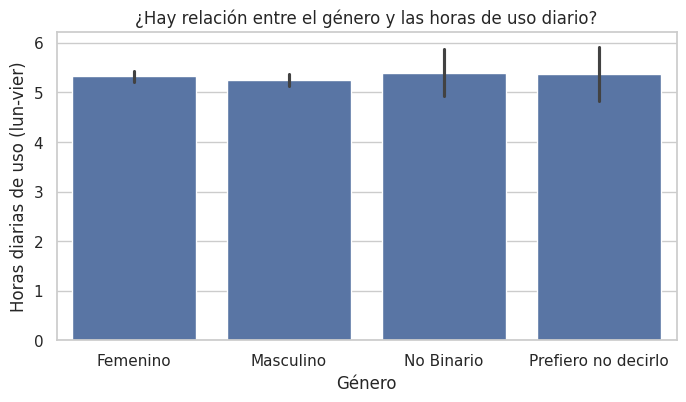

El gráfico de barras muestra que no hay diferencias significativas en las horas de uso diarias basadas en el género autopercibido.


In [35]:
# Comparación entre Género y Horas de Uso Diario
sns.barplot(x=df["Genero"], y=df["Horas_Uso_Diario"])
plt.title("¿Hay relación entre el género y las horas de uso diario?")
plt.xlabel("Género")
plt.ylabel("Horas diarias de uso (lun-vier)")
plt.show()

print("El gráfico de barras muestra que no hay diferencias significativas en las horas de uso diarias basadas en el género autopercibido.")

4.2. Uso de seaborn para visualizaciones más estilizadas y analíticas

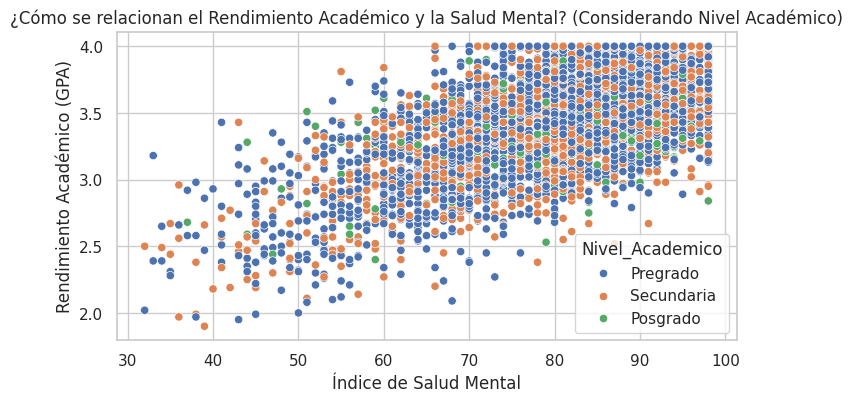

Es clara la relación positiva entre Indice de Salud Mental y Rendimiento Académico aunque no se perciban diferencias según nivel académico
(influye la distribución de la muestra: Pregrado	2777, Secundaria 1477, Posgrado	246)


In [36]:
sns.scatterplot(data=df, x="Indice_Salud_Mental", y="Rendimiento_Academico_GPA", hue="Nivel_Academico")
plt.title("¿Cómo se relacionan el Rendimiento Académico y la Salud Mental? (Considerando Nivel Académico)")
plt.xlabel("Índice de Salud Mental")
plt.ylabel("Rendimiento Académico (GPA)")
plt.show()
print("Es clara la relación positiva entre Indice de Salud Mental y Rendimiento Académico aunque no se perciban diferencias según nivel académico")
print("(influye la distribución de la muestra: Pregrado	2777, Secundaria 1477, Posgrado	246)")

In [37]:
fig = plt.gcf() #figura actual
fig.savefig("rend acad y salud mental")

<Figure size 800x400 with 0 Axes>

In [38]:
from google.colab import files

# Guardar el DataFrame traducido a un archivo CSV
# Usamos 'utf-8-sig' para asegurar que Power BI y Excel abran correctamente las tildes y caracteres en español
nombre_archivo = "Social_media_impact_on_life_es.csv"
df.to_csv(nombre_archivo, index=False, encoding="utf-8-sig")

# Iniciar la descarga del archivo en tu navegador
files.download(nombre_archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>